In [ ]:
"""
=============================================================
  TRANSFORMER FROM SCRATCH — Educational Implementation
=============================================================
  Based on "Attention Is All You Need" (Vaswani et al., 2017)

  Architecture Overview:
  ┌─────────────────────────────────────┐
  │           TRANSFORMER               │
  │  ┌──────────────┐  ┌─────────────┐ │
  │  │   ENCODER    │  │   DECODER   │ │
  │  │  (N layers)  │  │  (N layers) │ │
  │  └──────────────┘  └─────────────┘ │
  └─────────────────────────────────────┘
=============================================================
"""

import numpy as np

# ─────────────────────────────────────────────
# 1. SCALED DOT-PRODUCT ATTENTION
#    "Which parts of the input should I focus on?"
# ─────────────────────────────────────────────
def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Q (Query)  : What I'm looking for
    K (Key)    : What each position offers
    V (Value)  : The actual content at each position

    Steps:
      1. Compute similarity scores: Q · Kᵀ
      2. Scale by √d_k  (prevents vanishing gradients)
      3. Optional mask (for decoder)
      4. Softmax → attention weights
      5. Weighted sum of Values
    """
    d_k = Q.shape[-1]

    # Step 1 & 2: Scaled scores  (batch, heads, seq, seq)
    scores = np.matmul(Q, K.transpose(0, 1, 3, 2)) / np.sqrt(d_k)

    # Step 3: Apply mask (fill future positions with -inf so softmax → 0)
    if mask is not None:
        scores = np.where(mask == 0, -1e9, scores)

    # Step 4: Softmax over last axis
    scores -= scores.max(axis=-1, keepdims=True)   # numerical stability
    exp_scores = np.exp(scores)
    attention_weights = exp_scores / exp_scores.sum(axis=-1, keepdims=True)

    # Step 5: Weighted sum
    output = np.matmul(attention_weights, V)
    return output, attention_weights


# ─────────────────────────────────────────────
# 2. MULTI-HEAD ATTENTION
#    "Look at different aspects simultaneously"
# ─────────────────────────────────────────────
class MultiHeadAttention:
    """
    Instead of one big attention, use h smaller attentions in parallel.
    Each "head" can specialise (syntax, semantics, coreference, etc.)

    d_model → split into h heads of size d_k = d_model / h
    """
    def __init__(self, d_model=512, num_heads=8):
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.d_model    = d_model
        self.num_heads  = num_heads
        self.d_k        = d_model // num_heads

        # Weight matrices (random init for demo)
        scale = np.sqrt(2.0 / d_model)
        self.W_Q = np.random.randn(d_model, d_model) * scale
        self.W_K = np.random.randn(d_model, d_model) * scale
        self.W_V = np.random.randn(d_model, d_model) * scale
        self.W_O = np.random.randn(d_model, d_model) * scale

    def split_heads(self, x, batch_size):
        """Reshape (batch, seq, d_model) → (batch, heads, seq, d_k)"""
        x = x.reshape(batch_size, -1, self.num_heads, self.d_k)
        return x.transpose(0, 2, 1, 3)

    def forward(self, Q, K, V, mask=None):
        batch_size = Q.shape[0]

        # Project inputs
        Q = np.matmul(Q, self.W_Q)
        K = np.matmul(K, self.W_K)
        V = np.matmul(V, self.W_V)

        # Split into heads
        Q = self.split_heads(Q, batch_size)
        K = self.split_heads(K, batch_size)
        V = self.split_heads(V, batch_size)

        # Attention per head
        attn_output, attn_weights = scaled_dot_product_attention(Q, K, V, mask)

        # Concatenate heads back: (batch, heads, seq, d_k) → (batch, seq, d_model)
        attn_output = attn_output.transpose(0, 2, 1, 3)
        concat      = attn_output.reshape(batch_size, -1, self.d_model)

        # Final linear projection
        output = np.matmul(concat, self.W_O)
        return output, attn_weights


# ─────────────────────────────────────────────
# 3. POSITION-WISE FEED-FORWARD NETWORK
#    "Process each position independently"
# ─────────────────────────────────────────────
class FeedForward:
    """
    Two linear layers with ReLU in between.
    d_model → d_ff (expand) → d_model (contract)
    Typically d_ff = 4 × d_model
    """
    def __init__(self, d_model=512, d_ff=2048):
        scale = np.sqrt(2.0 / d_model)
        self.W1 = np.random.randn(d_model, d_ff)  * scale
        self.b1 = np.zeros(d_ff)
        self.W2 = np.random.randn(d_ff, d_model)  * scale
        self.b2 = np.zeros(d_model)

    def relu(self, x):
        return np.maximum(0, x)

    def forward(self, x):
        return self.relu(x @ self.W1 + self.b1) @ self.W2 + self.b2


# ─────────────────────────────────────────────
# 4. LAYER NORMALIZATION
#    "Stabilise activations across the layer"
# ─────────────────────────────────────────────
class LayerNorm:
    """Normalize each token's features to mean=0, std=1, then scale+shift."""
    def __init__(self, d_model=512, eps=1e-6):
        self.gamma = np.ones(d_model)   # learnable scale
        self.beta  = np.zeros(d_model)  # learnable shift
        self.eps   = eps

    def forward(self, x):
        mean = x.mean(axis=-1, keepdims=True)
        std  = x.std(axis=-1,  keepdims=True)
        return self.gamma * (x - mean) / (std + self.eps) + self.beta


# ─────────────────────────────────────────────
# 5. POSITIONAL ENCODING
#    "Tell the model where each token sits"
# ─────────────────────────────────────────────
def positional_encoding(seq_len, d_model):
    """
    Transformers have no recurrence, so we inject position info via
    sine / cosine waves of different frequencies.

    PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
    PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
    """
    PE = np.zeros((seq_len, d_model))
    pos = np.arange(seq_len).reshape(-1, 1)
    i   = np.arange(0, d_model, 2)
    div = np.power(10000, i / d_model)

    PE[:, 0::2] = np.sin(pos / div)
    PE[:, 1::2] = np.cos(pos / div)

    return PE   # (seq_len, d_model)


# ─────────────────────────────────────────────
# 6. ENCODER LAYER
#    Self-Attention → Add & Norm → FFN → Add & Norm
# ─────────────────────────────────────────────
class EncoderLayer:
    """
    One encoder block:
      x → [Self-Attention] → Add(x) → LayerNorm
        → [Feed-Forward]  → Add(x) → LayerNorm
    """
    def __init__(self, d_model=512, num_heads=8, d_ff=2048):
        self.self_attn = MultiHeadAttention(d_model, num_heads)
        self.ffn       = FeedForward(d_model, d_ff)
        self.norm1     = LayerNorm(d_model)
        self.norm2     = LayerNorm(d_model)

    def forward(self, x, mask=None):
        # Sub-layer 1: Self-attention + residual
        attn_out, _ = self.self_attn.forward(x, x, x, mask)
        x = self.norm1.forward(x + attn_out)           # Add & Norm

        # Sub-layer 2: Feed-forward + residual
        ffn_out = self.ffn.forward(x)
        x = self.norm2.forward(x + ffn_out)            # Add & Norm
        return x


# ─────────────────────────────────────────────
# 7. DECODER LAYER
#    Masked Self-Attention → Cross-Attention → FFN
# ─────────────────────────────────────────────
class DecoderLayer:
    """
    One decoder block adds CROSS-ATTENTION to attend to encoder output:
      x → [Masked Self-Attention] → Add & Norm
        → [Cross-Attention]       → Add & Norm  (keys/values from encoder)
        → [Feed-Forward]          → Add & Norm
    """
    def __init__(self, d_model=512, num_heads=8, d_ff=2048):
        self.self_attn  = MultiHeadAttention(d_model, num_heads)
        self.cross_attn = MultiHeadAttention(d_model, num_heads)
        self.ffn        = FeedForward(d_model, d_ff)
        self.norm1      = LayerNorm(d_model)
        self.norm2      = LayerNorm(d_model)
        self.norm3      = LayerNorm(d_model)

    def forward(self, x, enc_output, src_mask=None, tgt_mask=None):
        # Sub-layer 1: Masked self-attention (can't peek at future tokens)
        attn1, _ = self.self_attn.forward(x, x, x, tgt_mask)
        x = self.norm1.forward(x + attn1)

        # Sub-layer 2: Cross-attention (Q from decoder, K/V from encoder)
        attn2, _ = self.cross_attn.forward(x, enc_output, enc_output, src_mask)
        x = self.norm2.forward(x + attn2)

        # Sub-layer 3: Feed-forward
        ffn_out = self.ffn.forward(x)
        x = self.norm3.forward(x + ffn_out)
        return x


# ─────────────────────────────────────────────
# 8. FULL TRANSFORMER
# ─────────────────────────────────────────────
class Transformer:
    """
    Stack N encoder layers + N decoder layers.
    Used for sequence-to-sequence tasks (translation, summarisation, etc.)
    """
    def __init__(self, d_model=64, num_heads=4, d_ff=128, num_layers=2):
        self.d_model    = d_model
        self.num_layers = num_layers
        self.encoders   = [EncoderLayer(d_model, num_heads, d_ff) for _ in range(num_layers)]
        self.decoders   = [DecoderLayer(d_model, num_heads, d_ff) for _ in range(num_layers)]

    def encode(self, src, src_mask=None):
        for layer in self.encoders:
            src = layer.forward(src, src_mask)
        return src

    def decode(self, tgt, enc_output, src_mask=None, tgt_mask=None):
        for layer in self.decoders:
            tgt = layer.forward(tgt, enc_output, src_mask, tgt_mask)
        return tgt

    def forward(self, src, tgt, src_mask=None, tgt_mask=None):
        enc_output = self.encode(src, src_mask)
        dec_output = self.decode(tgt, enc_output, src_mask, tgt_mask)
        return dec_output


# ─────────────────────────────────────────────
# 9. DEMO — Run a forward pass
# ─────────────────────────────────────────────
if __name__ == "__main__":
    np.random.seed(42)

    # Hyperparameters (small for demo)
    BATCH_SIZE = 2
    SRC_SEQ    = 6    # source sequence length  (e.g. English sentence)
    TGT_SEQ    = 5    # target sequence length  (e.g. French sentence)
    D_MODEL    = 64   # embedding dimension
    NUM_HEADS  = 4
    D_FF       = 128
    NUM_LAYERS = 2

    print("=" * 55)
    print("  TRANSFORMER FORWARD PASS DEMO")
    print("=" * 55)

    # ── Simulate token embeddings (normally from an Embedding table)
    src = np.random.randn(BATCH_SIZE, SRC_SEQ, D_MODEL)
    tgt = np.random.randn(BATCH_SIZE, TGT_SEQ, D_MODEL)

    # ── Add positional encoding
    src += positional_encoding(SRC_SEQ, D_MODEL)
    tgt += positional_encoding(TGT_SEQ, D_MODEL)
    print(f"\n📥 Source shape : {src.shape}  (batch, src_seq, d_model)")
    print(f"📥 Target shape : {tgt.shape}  (batch, tgt_seq, d_model)")

    # ── Build Transformer
    model = Transformer(D_MODEL, NUM_HEADS, D_FF, NUM_LAYERS)

    # ── Causal mask for decoder (prevent attending to future tokens)
    #    Lower-triangular matrix of ones
    tgt_mask = np.tril(np.ones((1, 1, TGT_SEQ, TGT_SEQ)))

    # ── Forward pass
    output = model.forward(src, tgt, tgt_mask=tgt_mask)
    print(f"\n📤 Output shape : {output.shape}  (batch, tgt_seq, d_model)")

    # ── Show positional encoding pattern
    print("\n── Positional Encoding (first 4 dims, positions 0–5) ──")
    pe = positional_encoding(6, D_MODEL)
    print(np.round(pe[:, :4], 3))

    # ── Show attention weights from first encoder head
    attn_layer = model.encoders[0].self_attn
    _, weights = attn_layer.forward(src, src, src)
    print(f"\n── Attention weights shape : {weights.shape}")
    print("   (batch, heads, tgt_seq, src_seq)")
    print("\n── Head-0 attention matrix (batch 0) ──")
    print(np.round(weights[0, 0], 3))

    print("\n✅ Forward pass complete!")
    print("=" * 55)
    print("\nKEY CONCEPTS IMPLEMENTED:")
    print("  • Scaled Dot-Product Attention")
    print("  • Multi-Head Attention")
    print("  • Position-wise Feed-Forward Network")
    print("  • Layer Normalisation + Residual Connections")
    print("  • Positional Encoding (sin/cos)")
    print("  • Encoder stack")
    print("  • Decoder stack with Cross-Attention")
    print("  • Causal (look-ahead) mask")
    print("=" * 55)

  TRANSFORMER FORWARD PASS DEMO

📥 Source shape : (2, 6, 64)  (batch, src_seq, d_model)
📥 Target shape : (2, 5, 64)  (batch, tgt_seq, d_model)

📤 Output shape : (2, 5, 64)  (batch, tgt_seq, d_model)

── Positional Encoding (first 4 dims, positions 0–5) ──
[[ 0.     1.     0.     1.   ]
 [ 0.841  0.54   0.682  0.732]
 [ 0.909 -0.416  0.997  0.071]
 [ 0.141 -0.99   0.778 -0.628]
 [-0.757 -0.654  0.142 -0.99 ]
 [-0.959  0.284 -0.571 -0.821]]

── Attention weights shape : (2, 4, 6, 6)
   (batch, heads, tgt_seq, src_seq)

── Head-0 attention matrix (batch 0) ──
[[0.002 0.001 0.076 0.349 0.567 0.004]
 [0.006 0.    0.271 0.623 0.096 0.003]
 [0.013 0.253 0.183 0.224 0.316 0.011]
 [0.005 0.001 0.801 0.188 0.004 0.001]
 [0.696 0.158 0.085 0.017 0.035 0.008]
 [0.545 0.047 0.26  0.018 0.067 0.062]]

✅ Forward pass complete!

KEY CONCEPTS IMPLEMENTED:
  • Scaled Dot-Product Attention
  • Multi-Head Attention
  • Position-wise Feed-Forward Network
  • Layer Normalisation + Residual Connections
  • P

In [ ]:
!pip install gensim matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 52.1 MB/s eta 0:00:00


Loading GloVe (50d) embeddings...
[==================================================] 100.0% 66.0/66.0MB downloaded
Model loaded.
Selected 50 words.


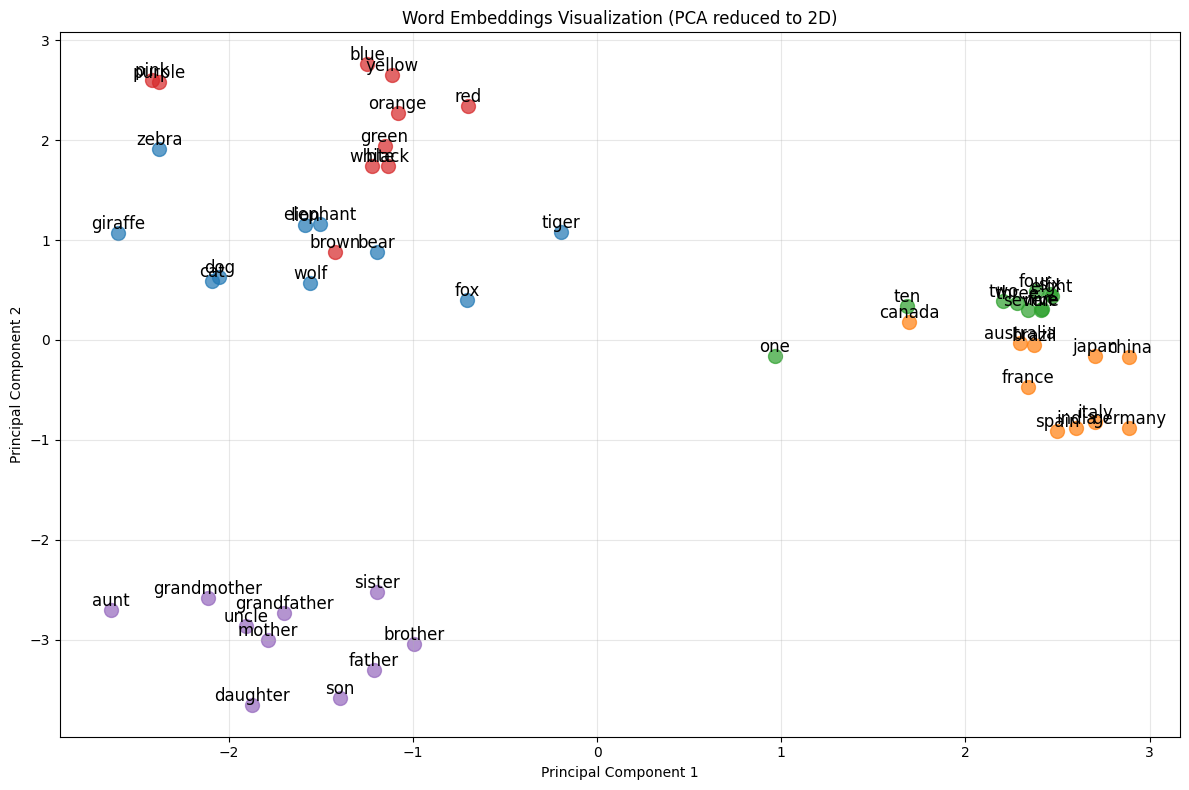


Vector analogy example:
 king - man + woman = queen
 paris - france + italy = rome


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import gensim.downloader as api

# ----------------------------------------------------------------------
# 1. Load a pre-trained word embedding model (50-dimensional GloVe)
#    This will download the model once (about 70 MB).
# ----------------------------------------------------------------------
print("Loading GloVe (50d) embeddings...")
model = api.load("glove-wiki-gigaword-50")   # 50-dimensional vectors
print("Model loaded.")

# ----------------------------------------------------------------------
# 2. Choose a list of words that belong to different semantic categories.
#    The model must contain these words; we'll filter later.
# ----------------------------------------------------------------------
word_categories = {
    "animals": ["dog", "cat", "lion", "tiger", "elephant", "zebra", "giraffe", "wolf", "fox", "bear"],
    "countries": ["france", "germany", "italy", "spain", "china", "japan", "india", "brazil", "canada", "australia"],
    "numbers": ["one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"],
    "colors": ["red", "blue", "green", "yellow", "purple", "orange", "black", "white", "brown", "pink"],
    "family": ["father", "mother", "brother", "sister", "son", "daughter", "grandfather", "grandmother", "uncle", "aunt"]
}

# ----------------------------------------------------------------------
# 3. Collect words that are actually present in the model.
# ----------------------------------------------------------------------
words = []
labels = []
colors = []
color_map = {
    "animals": "tab:blue",
    "countries": "tab:orange",
    "numbers": "tab:green",
    "colors": "tab:red",
    "family": "tab:purple"
}

for category, word_list in word_categories.items():
    for w in word_list:
        if w in model.key_to_index:   # check if word is in vocabulary
            words.append(w)
            labels.append(w)
            colors.append(color_map[category])
        else:
            print(f"Warning: '{w}' not in vocabulary, skipping.")

print(f"Selected {len(words)} words.")

# ----------------------------------------------------------------------
# 4. Create a matrix of word vectors.
# ----------------------------------------------------------------------
vectors = np.array([model[w] for w in words])   # shape: (n_words, 50)

# ----------------------------------------------------------------------
# 5. Reduce dimensionality to 2D using PCA.
#    (You can replace with TSNE for a more non-linear view, but PCA is faster.)
# ----------------------------------------------------------------------
pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)   # shape: (n_words, 2)

# ----------------------------------------------------------------------
# 6. Plot the words with colors per category.
# ----------------------------------------------------------------------
plt.figure(figsize=(12, 8))
for i, word in enumerate(words):
    x, y = vectors_2d[i]
    plt.scatter(x, y, color=colors[i], s=100, alpha=0.7)
    plt.text(x, y, word, fontsize=12, ha='center', va='bottom')

plt.title("Word Embeddings Visualization (PCA reduced to 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 7. Optional: Show a vector analogy example (king - man + woman ≈ queen)
# ----------------------------------------------------------------------
def analogy(a, b, c, model):
    """Returns the word closest to a - b + c."""
    try:
        result = model.most_similar(positive=[c, b], negative=[a])[0][0]
        return result
    except:
        return "unknown"

print("\nVector analogy example:")
print(" king - man + woman =", analogy("man", "king", "woman", model))
print(" paris - france + italy =", analogy("france", "paris", "italy", model))

Synthetic Example: Illustrating Magnitude Effect
v1           : [2. 1.]
v2 (2× v1)   : [4. 2.]
v3 (rotated) : [0.1339746  2.23205081]

Cosine similarity (v1, v2): 1.0000  (almost 1.0)
Cosine similarity (v1, v3): 0.5000

Euclidean distance (v1, v2): 2.2361  (large because magnitude differs)
Euclidean distance (v1, v3): 2.2361


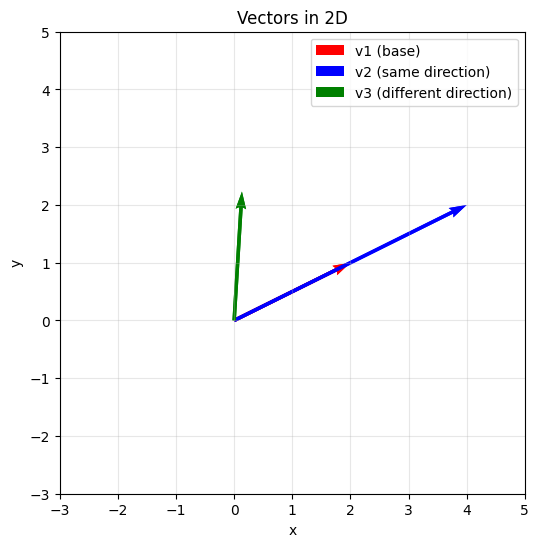


Observation: Cosine similarity ignores magnitude, while Euclidean distance does not.

Real-world Example with GloVe Embeddings
Model loaded.

Pair: 'dog' ↔ 'cat'
  Cosine similarity          : 0.9218
  Euclidean distance (raw)   : 1.8846
  Euclidean distance (normed): 0.3955
  Norm of 'dog': 4.8580, Norm of 'cat': 4.4079

Pair: 'king' ↔ 'queen'
  Cosine similarity          : 0.7839
  Euclidean distance (raw)   : 3.4778
  Euclidean distance (normed): 0.6574
  Norm of 'king': 5.3745, Norm of 'queen': 5.1928

Pair: 'car' ↔ 'automobile'
  Cosine similarity          : 0.6956
  Euclidean distance (raw)   : 4.2904
  Euclidean distance (normed): 0.7802
  Norm of 'car': 5.7301, Norm of 'automobile': 5.1950

Pair: 'good' ↔ 'bad'
  Cosine similarity          : 0.7965
  Euclidean distance (raw)   : 3.3189
  Euclidean distance (normed): 0.6380
  Norm of 'good': 5.2699, Norm of 'bad': 5.1256

Notice: Cosine similarity stays the same after normalization, Euclidean distance changes.
If you compare ra

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

# -------------------------------
# 1. Synthetic example
# -------------------------------
print("="*60)
print("Synthetic Example: Illustrating Magnitude Effect")
print("="*60)

# Create three vectors:
# v1: base vector
# v2: same direction as v1, but twice the magnitude
# v3: different direction (rotated by 60 degrees)
v1 = np.array([2.0, 1.0])
v2 = v1 * 2.0                     # same direction, double magnitude
angle = np.radians(60)
rot = np.array([[np.cos(angle), -np.sin(angle)],
                [np.sin(angle),  np.cos(angle)]])
v3 = rot @ v1                     # rotate v1 by 60°

# Normalize for comparison (optional)
v1_norm = v1 / np.linalg.norm(v1)
v2_norm = v2 / np.linalg.norm(v2)
v3_norm = v3 / np.linalg.norm(v3)

# Compute similarities / distances
cos_sim_v1_v2 = cosine_similarity([v1], [v2])[0][0]
cos_sim_v1_v3 = cosine_similarity([v1], [v3])[0][0]
euc_dist_v1_v2 = euclidean_distances([v1], [v2])[0][0]
euc_dist_v1_v3 = euclidean_distances([v1], [v3])[0][0]

print(f"v1           : {v1}")
print(f"v2 (2× v1)   : {v2}")
print(f"v3 (rotated) : {v3}")
print()
print(f"Cosine similarity (v1, v2): {cos_sim_v1_v2:.4f}  (almost 1.0)")
print(f"Cosine similarity (v1, v3): {cos_sim_v1_v3:.4f}")
print()
print(f"Euclidean distance (v1, v2): {euc_dist_v1_v2:.4f}  (large because magnitude differs)")
print(f"Euclidean distance (v1, v3): {euc_dist_v1_v3:.4f}")

# Plot the vectors in 2D
plt.figure(figsize=(6,6))
origin = np.zeros((2,2))
plt.quiver(*origin, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='r', label='v1 (base)')
plt.quiver(*origin, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='b', label='v2 (same direction)')
plt.quiver(*origin, v3[0], v3[1], angles='xy', scale_units='xy', scale=1, color='g', label='v3 (different direction)')
plt.xlim(-3, 5)
plt.ylim(-3, 5)
plt.grid(alpha=0.3)
plt.legend()
plt.title("Vectors in 2D")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

print("\nObservation: Cosine similarity ignores magnitude, while Euclidean distance does not.\n")

# -------------------------------
# 2. Real-world example using GloVe embeddings (if available)
# -------------------------------
try:
    import gensim.downloader as api
    print("="*60)
    print("Real-world Example with GloVe Embeddings")
    print("="*60)

    # Load a small pre-trained model (50-dimensional GloVe)
    model = api.load("glove-wiki-gigaword-50")
    print("Model loaded.\n")

    # Choose word pairs that are semantically related but may have different frequencies
    word_pairs = [("dog", "cat"), ("king", "queen"), ("car", "automobile"), ("good", "bad")]

    for w1, w2 in word_pairs:
        if w1 in model and w2 in model:
            vec1 = model[w1]
            vec2 = model[w2]

            # Cosine similarity (using sklearn)
            cos_sim = cosine_similarity([vec1], [vec2])[0][0]
            # Euclidean distance
            euc_dist = euclidean_distances([vec1], [vec2])[0][0]

            # Also compute normalized versions for illustration
            vec1_norm = vec1 / np.linalg.norm(vec1)
            vec2_norm = vec2 / np.linalg.norm(vec2)
            euc_dist_norm = euclidean_distances([vec1_norm], [vec2_norm])[0][0]

            print(f"Pair: '{w1}' ↔ '{w2}'")
            print(f"  Cosine similarity          : {cos_sim:.4f}")
            print(f"  Euclidean distance (raw)   : {euc_dist:.4f}")
            print(f"  Euclidean distance (normed): {euc_dist_norm:.4f}")
            print(f"  Norm of '{w1}': {np.linalg.norm(vec1):.4f}, Norm of '{w2}': {np.linalg.norm(vec2):.4f}")
            print()

    print("Notice: Cosine similarity stays the same after normalization, Euclidean distance changes.")
    print("If you compare raw Euclidean distances, words with large norms can be misleadingly far apart.")
except ImportError:
    print("\n(Optional) gensim not installed. To run the real-world example, install gensim: pip install gensim")

In [ ]:
!pip install sentence-transformers scikit-learn matplotlib numpy

Loading SBERT model...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (9 outputs left out)

Model loaded.

Number of sentences: 16

Encoding sentences...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding shape: (16, 384)  (num_sentences, embedding_dim)

Example Cosine Similarities:
  A dog is a man's best friend....  ↔  Cats are independent and grace...  =  0.2070
  Artificial intelligence will t...  ↔  Machine learning is a subset o...  =  0.4982
  Pizza is a beloved Italian dis...  ↔  Sushi originated in Japan and ...  =  0.2492
  Paris is known as the City of ...  ↔  Beach vacations are perfect fo...  =  0.0881

Query: "I love traveling to famous landmarks."
Top 3 most similar sentences in our collection:
  Traveling broadens your horizons. (score: 0.5279)
  Beach vacations are perfect for relaxation. (score: 0.3755)
  Paris is known as the City of Light. (score: 0.2785)

K‑Means Clustering (k=4):

Cluster 0:
    - Pizza is a beloved Italian dish.
    - Sushi originated in Japan and is now worldwide.
    - Chocolate is made from cocoa beans.
    - Fresh fruits are essential for a healthy diet.

Cluster 1:
    - A dog is a man's best friend.
    - Cats are independent and g

/tmp/ipython-input-3042057011.py:155: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


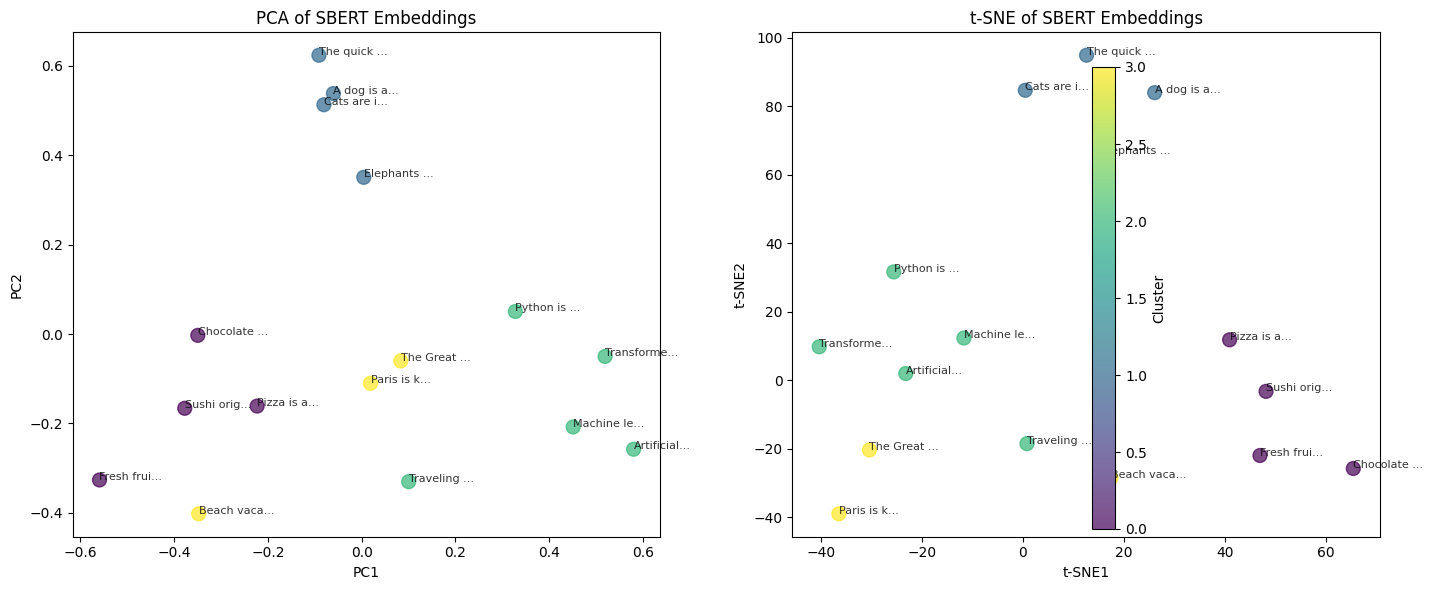


--- Analogy Example (conceptual) ---
Closest sentence to 'king - man + woman': A queen is a female ruler.
Similarity to actual 'queen' sentence: 0.7831

✅ Advanced SBERT demo completed!


In [ ]:
"""
=============================================================
   ADVANCED SBERT DEMO: Sentence Embeddings in Action
=============================================================
This script demonstrates:
  1. Loading a pre-trained Sentence-BERT model.
  2. Encoding sentences into dense vector embeddings.
  3. Computing cosine similarity between sentences.
  4. Finding the most similar sentences in a collection (semantic search).
  5. Clustering sentences by topic using k-means.
  6. Visualising the embedding space with PCA / t-SNE.
  7. (Optional) A simple analogy example using sentence embeddings.
=============================================================
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# ------------------------------
# 1. Load a pre-trained SBERT model
# ------------------------------
# 'all-MiniLM-L6-v2' is a small, fast model that still gives excellent results.
# Other popular choices: 'all-mpnet-base-v2' (higher quality, slower),
#                        'paraphrase-multilingual-MiniLM-L12-v2' (multilingual).
print("Loading SBERT model...")
model = SentenceTransformer('all-MiniLM-L6-v2')
print("Model loaded.\n")

# ------------------------------
# 2. Define a collection of sentences on various topics
# ------------------------------
sentences = [
    # Animals
    "A dog is a man's best friend.",
    "Cats are independent and graceful creatures.",
    "Elephants are the largest land animals.",
    "The quick brown fox jumps over the lazy dog.",
    # Technology
    "Artificial intelligence will transform the world.",
    "Machine learning is a subset of AI.",
    "Python is a popular programming language.",
    "Transformers revolutionized NLP.",
    # Food
    "Pizza is a beloved Italian dish.",
    "Sushi originated in Japan and is now worldwide.",
    "Chocolate is made from cocoa beans.",
    "Fresh fruits are essential for a healthy diet.",
    # Travel
    "Paris is known as the City of Light.",
    "The Great Wall of China is a wonder of the world.",
    "Traveling broadens your horizons.",
    "Beach vacations are perfect for relaxation."
]

print(f"Number of sentences: {len(sentences)}\n")

# ------------------------------
# 3. Encode sentences into embeddings
# ------------------------------
print("Encoding sentences...")
embeddings = model.encode(sentences, convert_to_numpy=True, show_progress_bar=True)
print(f"Embedding shape: {embeddings.shape}  (num_sentences, embedding_dim)\n")

# ------------------------------
# 4. Compute pairwise cosine similarities
# ------------------------------
similarity_matrix = cosine_similarity(embeddings)

# Print some example similarities
print("Example Cosine Similarities:")
pairs = [("A dog is a man's best friend.", "Cats are independent and graceful creatures."),
         ("Artificial intelligence will transform the world.", "Machine learning is a subset of AI."),
         ("Pizza is a beloved Italian dish.", "Sushi originated in Japan and is now worldwide."),
         ("Paris is known as the City of Light.", "Beach vacations are perfect for relaxation.")]

for s1, s2 in pairs:
    idx1 = sentences.index(s1)
    idx2 = sentences.index(s2)
    sim = similarity_matrix[idx1, idx2]
    print(f"  {s1[:30]}...  ↔  {s2[:30]}...  =  {sim:.4f}")

# ------------------------------
# 5. Semantic search: find the most similar sentences to a query
# ------------------------------
query = "I love traveling to famous landmarks."
print(f"\nQuery: \"{query}\"")
query_embedding = model.encode([query])
# Compute similarities between query and all sentences
query_sims = cosine_similarity(query_embedding, embeddings)[0]
# Get top 3 most similar sentences
top_indices = np.argsort(query_sims)[::-1][:3]
print("Top 3 most similar sentences in our collection:")
for idx in top_indices:
    print(f"  {sentences[idx]} (score: {query_sims[idx]:.4f})")

# ------------------------------
# 6. Clustering sentences with k-means
# ------------------------------
# We'll try to automatically group the sentences into topics.
# The true topics are: animals, technology, food, travel (4 clusters).
num_clusters = 4
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings)

print("\nK‑Means Clustering (k=4):")
for cluster_id in range(num_clusters):
    print(f"\nCluster {cluster_id}:")
    cluster_sentences = [sentences[i] for i, lbl in enumerate(cluster_labels) if lbl == cluster_id]
    for s in cluster_sentences:
        print(f"    - {s}")

# ------------------------------
# 7. Visualise the embedding space
# ------------------------------
# Because the embeddings are high‑dimensional (384 for MiniLM), we reduce to 2D.
print("\nReducing dimensions for visualisation...")

# PCA (linear) for a quick overview
pca = PCA(n_components=2)
embeddings_pca = pca.fit_transform(embeddings)

# t‑SNE (non‑linear) often reveals clusters better, but is slower
tsne = TSNE(n_components=2, perplexity=5, random_state=42, init='pca')
embeddings_tsne = tsne.fit_transform(embeddings)

# Plot both reductions side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Colour by cluster label from k‑means
scatter_pca = axes[0].scatter(embeddings_pca[:, 0], embeddings_pca[:, 1],
                              c=cluster_labels, cmap='viridis', s=100, alpha=0.7)
axes[0].set_title("PCA of SBERT Embeddings")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
# Annotate some points with the first few words
for i, sentence in enumerate(sentences):
    axes[0].annotate(sentence[:10]+"...", (embeddings_pca[i, 0], embeddings_pca[i, 1]),
                     fontsize=8, alpha=0.8)

scatter_tsne = axes[1].scatter(embeddings_tsne[:, 0], embeddings_tsne[:, 1],
                                c=cluster_labels, cmap='viridis', s=100, alpha=0.7)
axes[1].set_title("t‑SNE of SBERT Embeddings")
axes[1].set_xlabel("t‑SNE1")
axes[1].set_ylabel("t‑SNE2")
for i, sentence in enumerate(sentences):
    axes[1].annotate(sentence[:10]+"...", (embeddings_tsne[i, 0], embeddings_tsne[i, 1]),
                     fontsize=8, alpha=0.8)

plt.colorbar(scatter_tsne, ax=axes, label='Cluster')
plt.tight_layout()
plt.show()

# ------------------------------
# 8. (Optional) Simple analogy with sentence embeddings
# ------------------------------
# While SBERT isn't designed for word‑like analogies, we can try an example:
#   "king" - "man" + "woman" ≈ "queen" – but using sentences that embed those concepts.
print("\n--- Analogy Example (conceptual) ---")
analogy_sentences = [
    "A king is a male ruler.",
    "A man is an adult male.",
    "A woman is an adult female.",
    "A queen is a female ruler."
]
ana_embeddings = model.encode(analogy_sentences)

# Compute vector: king - man + woman
king_vec = ana_embeddings[0]
man_vec = ana_embeddings[1]
woman_vec = ana_embeddings[2]
queen_vec = ana_embeddings[3]

result_vec = king_vec - man_vec + woman_vec

# Find which of the original sentences is closest to the result vector
similarities = cosine_similarity([result_vec], ana_embeddings)[0]
closest_idx = np.argmax(similarities)
print(f"Closest sentence to 'king - man + woman': {analogy_sentences[closest_idx]}")
print(f"Similarity to actual 'queen' sentence: {similarities[3]:.4f}")

print("\n✅ Advanced SBERT demo completed!")

In [ ]:
Index techniques : FAISS and Chroma DB : FlatL2, IVF, HNSW